# Hierarchical clustering — build a tree one merge at a time

**Introductory lab · 30–40 minutes**

Six hand-built map locations make all five merges visible. Both coordinates use the same units. We start with one group per location and repeatedly merge the closest groups.

Run cells in order in Jupyter or Colab. All data are embedded. If dependencies are missing, uncomment the installation command. Predict each result before running the next step.

In [1]:
# %pip install numpy pandas matplotlib scipy scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import adjusted_rand_score, silhouette_score
plt.rcParams.update({'figure.figsize': (7, 5), 'font.size': 11})


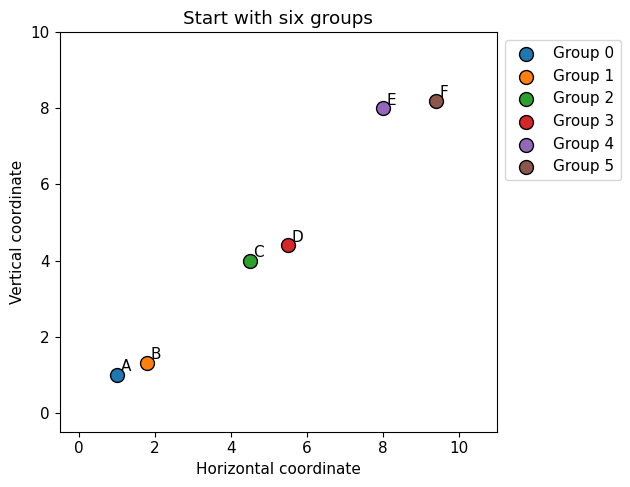

In [3]:
X = np.array([[1,1],[1.8,1.3],[4.5,4],[5.5,4.4],[8,8],[9.4,8.2]])
names = np.array(list('ABCDEF'))
def plot_groups(points, groups, title, centers=None):
    fig, ax = plt.subplots()
    for group in np.unique(groups):
        selected = groups == group
        color = 'lightgray' if group < 0 else plt.cm.tab10(int(group) % 10)
        ax.scatter(points[selected,0], points[selected,1], s=100, color=color,
                   edgecolor='black', label=f'Group {group}' if group >= 0 else 'Unassigned / noise')
    for i, point in enumerate(points):
        ax.annotate(names[i], point + .10)
    if centers is not None:
        ax.scatter(centers[:,0], centers[:,1], marker='X', s=260, c='red', label='Centroids')
    ax.set(xlabel='Horizontal coordinate', ylabel='Vertical coordinate', title=title)
    ax.set_xlim(-.5, 11); ax.set_ylim(-.5, 10); ax.set_aspect('equal')
    ax.legend(loc='upper left', bbox_to_anchor=(1,1)); plt.tight_layout(); plt.show()
plot_groups(X, np.arange(len(X)), 'Start with six groups')

## 1. Define distance between groups
We use **single linkage**, the shortest distance between any member of one group and any member of another.
$$d(A,B)=\min_{i\in A,j\in B}\|x_i-x_j\|.$$
A group can therefore grow through a chain of nearby points. At each step inspect the group-distance table, predict the smallest value, and examine the merged result.

,A,B,C,D,E,F
A,inf,0.854,4.610,5.640,9.899,11.063
B,0.854,inf,3.818,4.827,9.129,10.265
C,4.610,3.818,inf,1.077,5.315,6.454
D,5.640,4.827,1.077,inf,4.383,5.445
E,9.899,9.129,5.315,4.383,inf,1.414
F,11.063,10.265,6.454,5.445,1.414,inf


Merge A + B at distance 0.854


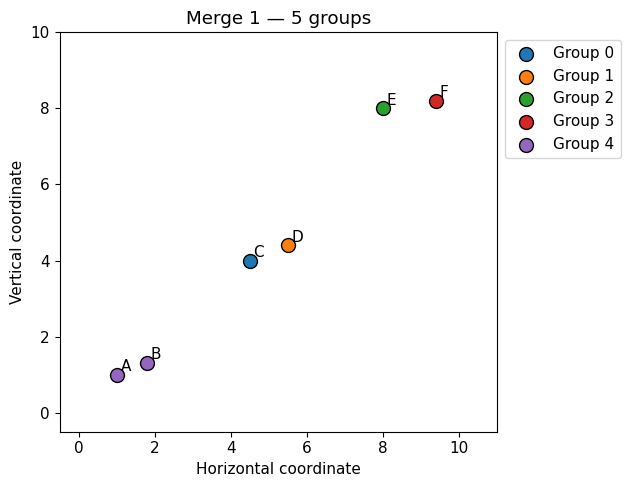

,C,D,E,F,AB
C,inf,1.077,5.315,6.454,3.818
D,1.077,inf,4.383,5.445,4.827
E,5.315,4.383,inf,1.414,9.129
F,6.454,5.445,1.414,inf,10.265
AB,3.818,4.827,9.129,10.265,inf


Merge C + D at distance 1.077


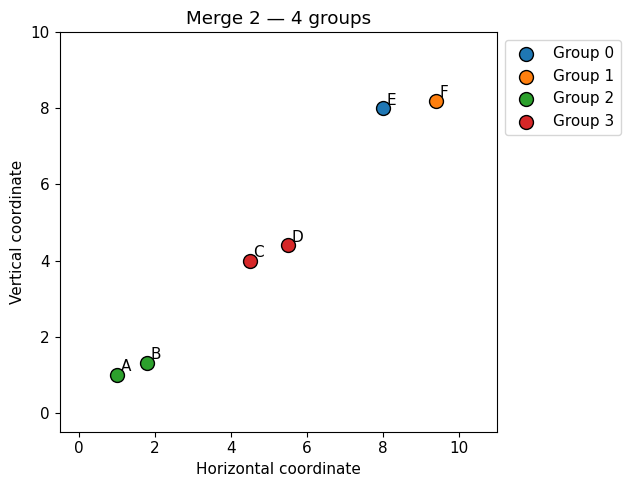

,E,F,AB,CD
E,inf,1.414,9.129,4.383
F,1.414,inf,10.265,5.445
AB,9.129,10.265,inf,3.818
CD,4.383,5.445,3.818,inf


Merge E + F at distance 1.414


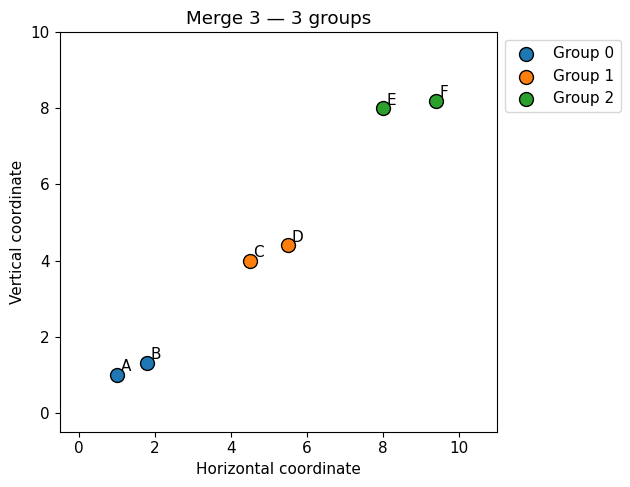

,AB,CD,EF
AB,inf,3.818,9.129
CD,3.818,inf,4.383
EF,9.129,4.383,inf


Merge AB + CD at distance 3.818


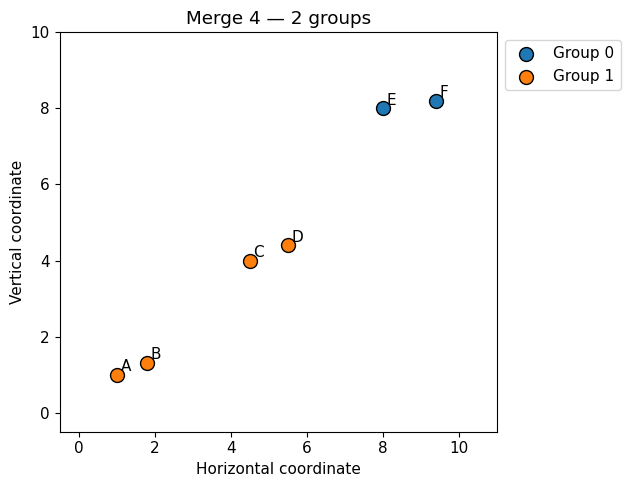

,EF,ABCD
EF,inf,4.383
ABCD,4.383,inf


Merge EF + ABCD at distance 4.383


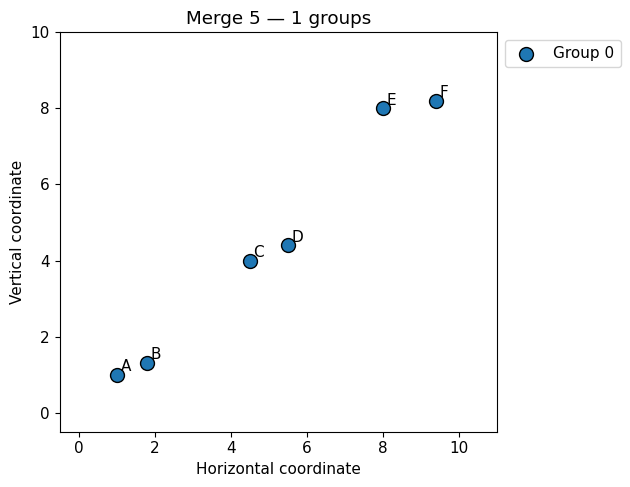

In [4]:
from scipy.spatial.distance import cdist
D = cdist(X,X)
groups = {i:[i] for i in range(len(X))}
linkage_rows = []
partitions = {len(X):np.arange(len(X))}
for step in range(len(X)-1):
    keys = list(groups)
    distances = np.full((len(keys),len(keys)),np.inf)
    for a in range(len(keys)):
        for b in range(a+1,len(keys)):
            value = D[np.ix_(groups[keys[a]],groups[keys[b]])].min()
            distances[a,b] = distances[b,a] = value
    group_names = [''.join(names[groups[key]]) for key in keys]
    display(pd.DataFrame(distances,index=group_names,columns=group_names).round(3))
    a,b = np.unravel_index(distances.argmin(),distances.shape)
    left,right = keys[a],keys[b]
    merged = groups[left]+groups[right]
    height = distances[a,b]
    print(f'Merge {group_names[a]} + {group_names[b]} at distance {height:.3f}')
    linkage_rows.append([left,right,height,len(merged)])
    del groups[left],groups[right]
    groups[len(X)+step] = merged
    labels = np.empty(len(X),dtype=int)
    for label,members in enumerate(groups.values()): labels[members] = label
    partitions[len(groups)] = labels.copy()
    plot_groups(X,labels,f'Merge {step+1} — {len(groups)} groups')
manual_linkage = np.array(linkage_rows)


## 2. Read the dendrogram
Leaves are individual observations. A vertical merge height records the single-linkage distance. A horizontal cut defines groups by the branches it intersects. Try cuts at 2 and 4.

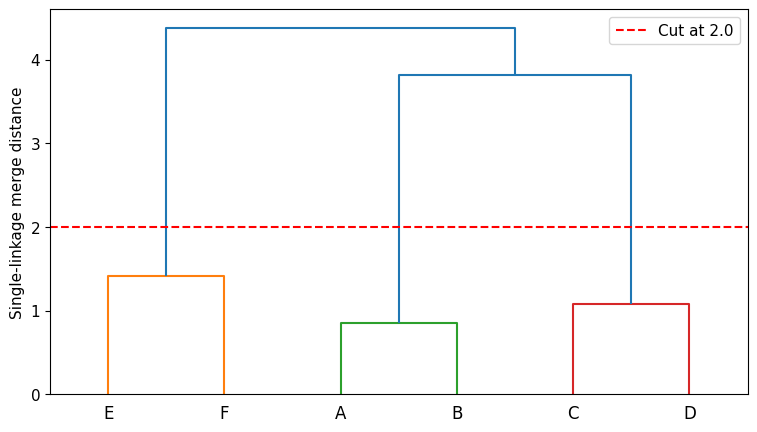

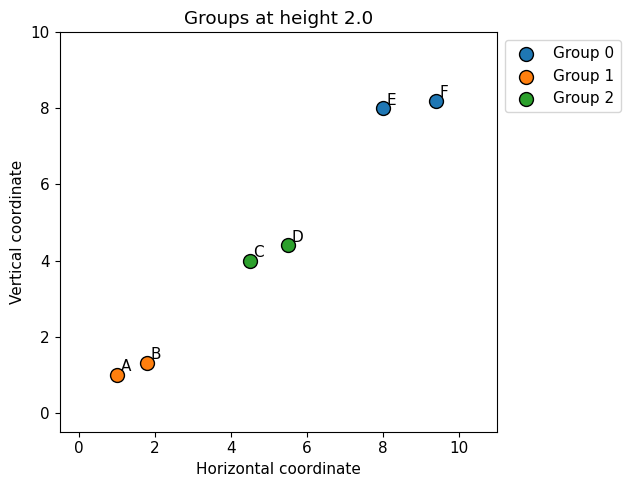

In [5]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
cut = 2.0
fig, ax = plt.subplots(figsize=(9,5))
dendrogram(manual_linkage,labels=names.tolist(),ax=ax,color_threshold=cut)
ax.axhline(cut,color='red',linestyle='--',label=f'Cut at {cut}')
ax.set_ylabel('Single-linkage merge distance'); ax.legend(); plt.show()
cut_labels = fcluster(manual_linkage,t=cut,criterion='distance')-1
plot_groups(X,cut_labels,f'Groups at height {cut}')


## 3. Verify the tree and three-group partition
The same linkage rule must be used in the manual and library calculations.

In [ ]:
from sklearn.cluster import AgglomerativeClustering

library_linkage = linkage(X,method='single') # single-linkage hierarchical clustering

assert np.allclose(manual_linkage,library_linkage)
library_labels = AgglomerativeClustering(n_clusters=3,linkage='single').fit_predict(X)
assert adjusted_rand_score(partitions[3],library_labels) == 1
print('Verified every merge and the three-group partition.')


Verified every merge and the three-group partition.


## 4. How the linkage rule changes the question
| Rule | Which groups merge? |
|---|---|
| Single | Closest pair of members |
| Complete | Smallest maximum pairwise distance |
| Average | Smallest average pairwise distance |
| Ward | Smallest increase in within-group squared error |

The final Wholesale Customers notebook uses Ward to encourage compact groups. Its merge heights use a different criterion from this single-linkage example.

**Practice** Move C closer to B and rerun. Predict how the tree changes. Why does a tree offer several levels of segmentation?

<details><summary>Instructor notes</summary>
The initial example gives three pairs at a cut of 2. A cut of 4 joins the first two pairs. Merges are irreversible in this agglomerative procedure. A dendrogram exposes nested resolutions, while a linkage rule determines what proximity means between groups. Ties may yield different merge orders.
</details>

Reference — [scikit-learn hierarchical clustering](https://scikit-learn.org/stable/modules/clustering.html#hierarchical-clustering).